In [117]:
import numpy as np
import pandas as pd

# DATA COLLECTION>>>

In [ ]:
#load dataset....
df=pd.read_csv(r"C:\Users\balar\OneDrive\personal practice\python_libraries\scikit_learn\Student-Performance-Predictor\StudentPerformanceFactors.csv")


,Hours_Studied,Attendance,Previous_Scores,Exam_Score
0,23,84,73,67
1,19,64,59,61
2,24,98,91,74
3,29,89,98,71
4,19,92,65,70


# DATA UNDERSTANDING AND EDA

In [141]:
print(df.head())
print(df.shape)
print(df.columns)

   Hours_Studied  Attendance  Previous_Scores  Exam_Score
0             23          84               73          67
1             19          64               59          61
2             24          98               91          74
3             29          89               98          71
4             19          92               65          70
(6607, 4)
Index(['Hours_Studied', 'Attendance', 'Previous_Scores', 'Exam_Score'], dtype='str')


In [120]:
print(df.info())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Hours_Studied    6607 non-null   int64
 1   Attendance       6607 non-null   int64
 2   Previous_Scores  6607 non-null   int64
 3   Exam_Score       6607 non-null   int64
dtypes: int64(4)
memory usage: 206.6 KB
None
       Hours_Studied   Attendance  Previous_Scores   Exam_Score
count    6607.000000  6607.000000      6607.000000  6607.000000
mean       19.975329    79.977448        75.070531    67.235659
std         5.990594    11.547475        14.399784     3.890456
min         1.000000    60.000000        50.000000    55.000000
25%        16.000000    70.000000        63.000000    65.000000
50%        20.000000    80.000000        75.000000    67.000000
75%        24.000000    90.000000        88.000000    69.000000
max        44.000000   100.000000       100.000000   101.000000


In [121]:
print(df[["Hours_Studied", "Attendance",
          "Previous_Scores", "Exam_Score"]].corr())

                 Hours_Studied  Attendance  Previous_Scores  Exam_Score
Hours_Studied         1.000000   -0.009908         0.024846    0.445455
Attendance           -0.009908    1.000000        -0.020186    0.581072
Previous_Scores       0.024846   -0.020186         1.000000    0.175079
Exam_Score            0.445455    0.581072         0.175079    1.000000


# FEATURES AND TARGET SELECTION>>>

In [122]:
#selecting inputs and target 
features=df.iloc[:,0:3]
target=df.iloc[:,3]
target=pd.DataFrame(target)

In [123]:
print(features.head())
print(target.head())

   Hours_Studied  Attendance  Previous_Scores
0             23          84               73
1             19          64               59
2             24          98               91
3             29          89               98
4             19          92               65
   Exam_Score
0          67
1          61
2          74
3          71
4          70


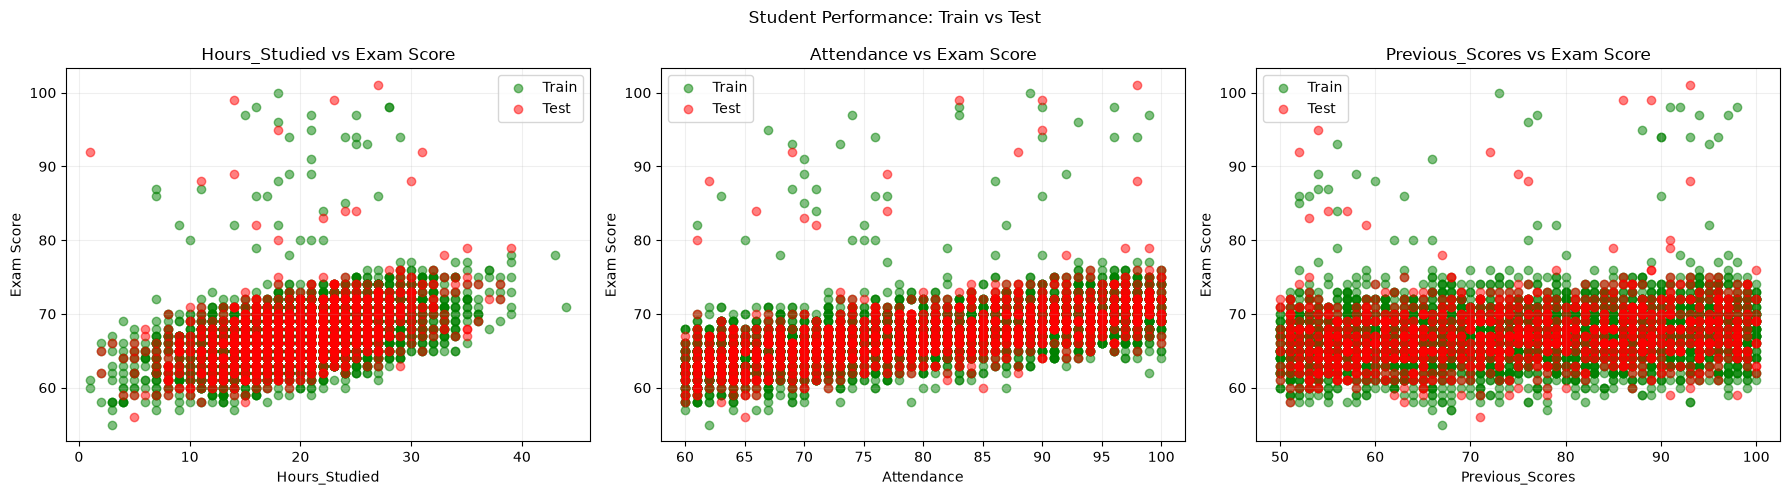

In [124]:
#visualising features relationship with target...
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, X_train.columns):

    ax.scatter(
        X_train[col], y_train,
        color="green", alpha=0.5,
        label="Train"
    )

    ax.scatter(
        X_test[col], y_test,
        color="red", alpha=0.5,
        label="Test"
    )

    ax.set_xlabel(col)
    ax.set_ylabel("Exam Score")
    ax.set_title(f"{col} vs Exam Score")
    ax.legend()
    ax.grid(alpha=0.2)

plt.suptitle("Student Performance: Train vs Test")
plt.tight_layout()
plt.show()

In [125]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error,r2_score

In [126]:
import matplotlib.pyplot as plt
import plotly.express as px

In [127]:
#splitting data into training and testing sets....
X_train,X_test,y_train,y_test=train_test_split(features,
                                               target,
                                               test_size=0.2,
                                               random_state=2)

# MODEL COMPARISON>>>>

In [128]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

for degree in range(1, 7):

    poly = PolynomialFeatures(
        degree=degree,
        include_bias=False
    )

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    train_pred = model.predict(X_train_poly)
    test_pred = model.predict(X_test_poly)

    print(f"\nDegree: {degree}")
    print("Train R2:", round(r2_score(y_train, train_pred), 4))
    print("Test R2:", round(r2_score(y_test, test_pred), 4))
    print("Test MAE:", round(mean_absolute_error(y_test, test_pred), 4))


Degree: 1
Train R2: 0.5887
Test R2: 0.5156
Test MAE: 1.4631

Degree: 2
Train R2: 0.5895
Test R2: 0.5142
Test MAE: 1.4708

Degree: 3
Train R2: 0.5894
Test R2: 0.5136
Test MAE: 1.4719

Degree: 4
Train R2: 0.5897
Test R2: 0.5097
Test MAE: 1.4768

Degree: 5
Train R2: 0.5892
Test R2: 0.5082
Test MAE: 1.4814

Degree: 6
Train R2: 0.588
Test R2: 0.506
Test MAE: 1.4892


In [129]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

model_rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)

train_pred = model_rf.predict(X_train)
test_pred = model_rf.predict(X_test)

print("Train R2:", round(r2_score(y_train, train_pred), 4))
print("Test R2:", round(r2_score(y_test, test_pred), 4))
print("Test MAE:", round(mean_absolute_error(y_test, test_pred), 4))

c:\Users\balar\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Train R2: 0.6869
Test R2: 0.4981
Test MAE: 1.5476


In [130]:
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error

model_ridge = Ridge(alpha=10)

model_ridge.fit(X_train, y_train)

ridge_pred = model_ridge.predict(X_test)

print("Ridge Test R2:", round(r2_score(y_test, ridge_pred), 4))
print("Ridge Test MAE:", round(mean_absolute_error(y_test, ridge_pred), 4))

Ridge Test R2: 0.5156
Ridge Test MAE: 1.4631


# MODEL SELECTION>>>>

In [131]:
poly=PolynomialFeatures(degree=1,include_bias=False)
X_train_trans=poly.fit_transform(X_train)
X_test_trans=poly.transform(X_test)

In [132]:
print(X_train.iloc[0])
print(X_train_trans[0])

Hours_Studied      31
Attendance         63
Previous_Scores    86
Name: 622, dtype: int64
[31. 63. 86.]


In [133]:
model=LinearRegression()

In [134]:
model.fit(X_train_trans,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 3)","[[0.29,0.2 ,0.05]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[41.93]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[1046.88, 839.79, 436.44]"


In [135]:
y_train_pred=model.predict(X_train_trans)

In [137]:
y_test_pred=model.predict(X_test_trans)
y_test_pred

array([[68.34441911],
       [66.17432236],
       [72.23706405],
       ...,
       [67.07493411],
       [69.02110881],
       [64.8155316 ]], shape=(1322, 1))

# CROSS VALIDATION>>>

In [139]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    model, X_train_trans, y_train,
    cv=5,
    scoring="r2"
)

print("R2 scores:", scores)
print("Mean CV R2:", round(scores.mean(), 4))

R2 scores: [0.59631491 0.51549539 0.5810385  0.62205866 0.64086091]
Mean CV R2: 0.5912


# FINAL REPORT>>>

In [142]:
print("train MAE:", mean_absolute_error(y_train,y_train_pred))
print("train R2 score: ",r2_score(y_train,y_train_pred))

train MAE: 1.4065047551775416
train R2 score:  0.58866716891561


In [144]:
print("test MAE:", mean_absolute_error(y_test,y_test_pred))
print("test R2 score: ",r2_score(y_test,y_test_pred))

test MAE: 1.4631449946595396
test R2 score:  0.5156126570038431


In [145]:
import pickle

with open("model.pkl","wb") as file:
    pickle.dump(model,file)